Kullanılan Cihaz: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 140MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 35.0MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 95.4MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.13MB/s]


Epoch [1/15] - Train Loss: 0.2477, Train Acc: %92.61 | Val Loss: 0.1370, Val Acc: %96.06
Epoch [2/15] - Train Loss: 0.1016, Train Acc: %96.84 | Val Loss: 0.1262, Val Acc: %96.06
Epoch [3/15] - Train Loss: 0.0693, Train Acc: %97.88 | Val Loss: 0.1052, Val Acc: %96.84
Epoch [4/15] - Train Loss: 0.0516, Train Acc: %98.31 | Val Loss: 0.0992, Val Acc: %97.16
Epoch [5/15] - Train Loss: 0.0420, Train Acc: %98.61 | Val Loss: 0.0951, Val Acc: %97.43
Epoch [6/15] - Train Loss: 0.0330, Train Acc: %98.86 | Val Loss: 0.1261, Val Acc: %96.62
Epoch [7/15] - Train Loss: 0.0306, Train Acc: %98.96 | Val Loss: 0.0968, Val Acc: %97.54
Epoch [8/15] - Train Loss: 0.0242, Train Acc: %99.19 | Val Loss: 0.0982, Val Acc: %97.48
Epoch [9/15] - Train Loss: 0.0255, Train Acc: %99.15 | Val Loss: 0.1024, Val Acc: %97.60
Epoch [10/15] - Train Loss: 0.0196, Train Acc: %99.34 | Val Loss: 0.1080, Val Acc: %97.29
Epoch [11/15] - Train Loss: 0.0206, Train Acc: %99.30 | Val Loss: 0.0974, Val Acc: %97.76
Epoch [12/15] - Tra

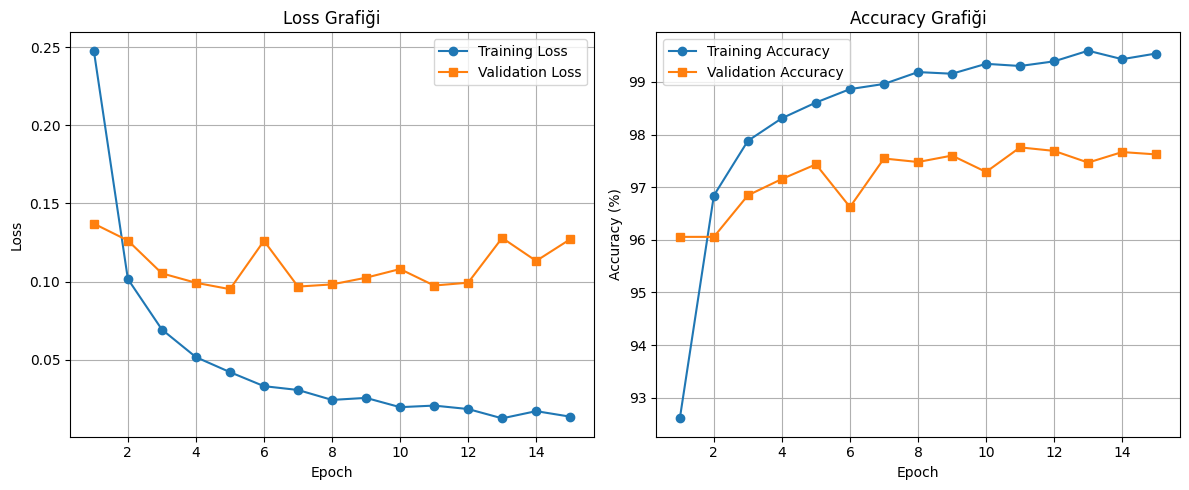

In [1]:
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps

# 1. CİHAZ SEÇİMİ VE HİPERPARAMETRELER
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Kullanılan Cihaz: {device}")

BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 15
INPUT_SIZE = 28 * 28  # 784
HIDDEN1_SIZE = 256
HIDDEN2_SIZE = 128
NUM_CLASSES = 10

# 2. VERİ SETİ YÜKLEME VE AYIRMA (Train %85, Val %15, Test)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_size = int(0.85 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 3. MİMARİ (MLP)
class MLPDigitClassifier(nn.Module):
    def __init__(self, input_dim, hidden1, hidden2, output_dim):
        super(MLPDigitClassifier, self).__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, output_dim)
        )

    def forward(self, x):
        return self.network(x)

model = MLPDigitClassifier(INPUT_SIZE, HIDDEN1_SIZE, HIDDEN2_SIZE, NUM_CLASSES).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# 4. EĞİTİM (TRAINING LOOP)
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
start_time = time.time()

for epoch in range(EPOCHS):
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = (correct_train / total_train) * 100

    model.eval()
    val_running_loss, correct_val, total_val = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / total_val
    epoch_val_acc = (correct_val / total_val) * 100

    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_acc'].append(epoch_val_acc)

    print(f"Epoch [{epoch+1}/{EPOCHS}] - Train Loss: {epoch_train_loss:.4f}, Train Acc: %{epoch_train_acc:.2f} | Val Loss: {epoch_val_loss:.4f}, Val Acc: %{epoch_val_acc:.2f}")

training_duration = time.time() - start_time
print(f"\nEğitim Süresi: {training_duration:.2f} saniye")

# 5. TEST KÜMESİ İLE DEĞERLENDİRME
model.eval()
test_running_loss, correct_test, total_test = 0.0, 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        test_running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_test += labels.size(0)
        correct_test += (predicted == labels).sum().item()

print(f"\n--- TEST SONUÇLARI ---")
print(f"Test Loss: {test_running_loss / total_test:.4f}")
print(f"Test Accuracy: %{(correct_test / total_test) * 100:.2f}")

# 6. GRAFİK ÇİZİMİ
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(1, EPOCHS + 1), history['train_loss'], label='Training Loss', marker='o')
plt.plot(range(1, EPOCHS + 1), history['val_loss'], label='Validation Loss', marker='s')
plt.title('Loss Grafiği')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(1, EPOCHS + 1), history['train_acc'], label='Training Accuracy', marker='o')
plt.plot(range(1, EPOCHS + 1), history['val_acc'], label='Validation Accuracy', marker='s')
plt.title('Accuracy Grafiği')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('loss_accuracy_graph.png')
plt.show()

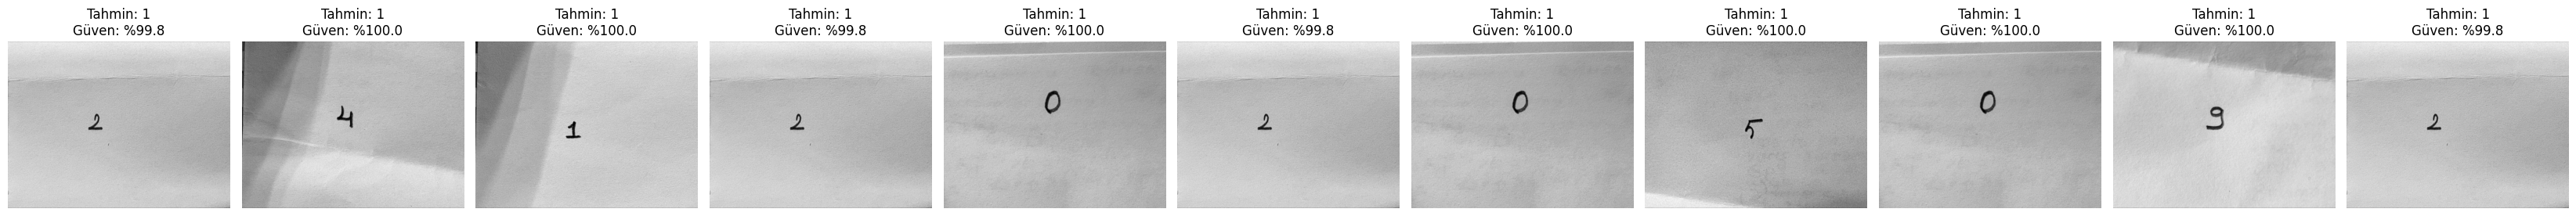

In [5]:
# 1. Fotoğrafları işleyip tahmin eden fonksiyonu tanımlıyoruz
def preprocess_and_predict(image_paths):
    model.eval()
    plt.figure(figsize=(len(image_paths) * 3, 3))

    for idx, path in enumerate(image_paths):
        if not os.path.exists(path):
            print(f"Hata: '{path}' adında bir dosya bulunamadı! Dosya adını kontrol edin.")
            continue

        # Görsel işleme (MNIST formatına çevirme)
        img = Image.open(path).convert('L')
        img_inverted = ImageOps.invert(img) # Siyah arka plan, beyaz yazıya çevirir
        img_resized = img_inverted.resize((28, 28), Image.Resampling.LANCZOS)

        tensor_img = transforms.ToTensor()(img_resized)
        tensor_img = transforms.Normalize((0.1307,), (0.3081,))(tensor_img).unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(tensor_img)
            probs = torch.softmax(output, dim=1)
            pred_class = torch.argmax(probs, dim=1).item()
            confidence = probs[0][pred_class].item() * 100

        plt.subplot(1, len(image_paths), idx + 1)
        plt.imshow(img, cmap='gray')
        plt.title(f"Tahmin: {pred_class}\nGüven: %{confidence:.1f}")
        plt.axis('off')

    plt.tight_layout()
    plt.savefig('custom_predictions.png')
    plt.show()

# 2. BURAYI DÜZENLEYİN: Yüklediğiniz dosyaların isimlerini tırnak içine yazın
# Örneğin fotoğraflarınızın adı 2.jpg, 0.jpg, 1.jpg ise:
my_digit_files = [
    '2.jpeg', '4.jpeg', '1.jpeg', '2.jpeg',
    '0.jpeg', '2.jpeg', '0.jpeg', '5.jpeg',
    '0.jpeg', '9.jpeg', '2.jpeg'
]

# Tahmini çalıştırıyoruz
preprocess_and_predict(my_digit_files)